# Linear Regression

### Goal

Predict a continuous target variable, assuming a linear relationship between the input features $X$ and the target variable $Y$.

$$
\hat{Y} = Xw + b
$$

### Loss Function

Measure the squared difference between the predicted value and the actual value for a single example.

$$
L = (\hat{y} - y)^2
$$

### Cost Function

Compute the average loss across $n$ training examples.

$$
J(w,b) = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

### Optimization

The parameters $w$ and $b$ are optimized using Gradient Descent to minimize the cost function and improve the predictions.

$$
w \leftarrow w - \alpha \frac{\partial J}{\partial w}
$$

$$
b \leftarrow b - \alpha \frac{\partial J}{\partial b}
$$

With the gradients:

$$
\frac{\partial J}{\partial w}
= \frac{2}{n}X^T(Xw+b-Y)
$$

$$
\frac{\partial J}{\partial b}
= \frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)
$$

Here, $\alpha$ is the learning rate, a hyperparameter that controls the step size during each parameter update in the direction opposite to the gradient.

In [139]:
import numpy as np

In [140]:
class LinearRegression():

    def __init__(self, max_iterations=1000, lr=0.01, reg=None, lam=1, epsilon=1e-5):
        self.max_iterations=max_iterations
        self.lr=lr
        self.reg = reg
        self.lam = lam
        self.epsilon = epsilon
        self.losses = []

    def fit(self,X,y):
        self.n, self.d = X.shape
        self.w = np.zeros(self.d)
        self.b = 0
        self.X = X
        self.y = y

        for i in range(self.max_iterations):
            y_hat = self.predict(self.X)
            loss = np.sum((self.y - y_hat) ** 2) / self.n
            self.losses.append(loss)
            dw = (np.dot(self.X.T, (y_hat - y)))/self.n
            db = np.sum(y_hat - y)/self.n
            if self.reg == "l2":
              dw += (self.lam / n) * w
            if self.reg == "l1":
              dw += (self.lam / n) * np.sign(w)
            new_w = self.w - self.lr * dw
            new_b = self.b - self.lr * db
            if np.all(np.abs(new_w - self.w) <= self.epsilon) and abs(new_b - self.b) <= self.epsilon:
               return self.w, self.b
            else:
               self.w = new_w
               self.b = new_b

        return self.w, self.b

    def predict(self, x):
        return np.dot(x, self.w) + self.b


In [141]:
np.random.seed(42)

n = 100
true_m, true_b = 2.5, 1.0
x = np.random.randn(n) * 5
noise = np.random.randn(n) * 1.2
y = true_m * x + true_b + noise

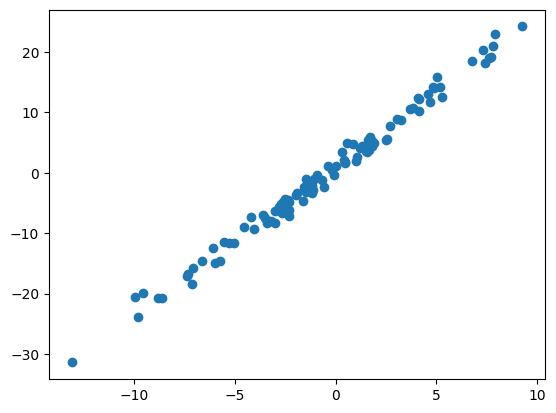

In [142]:
import matplotlib.pyplot as plt

plt.scatter(x,y)

In [143]:
x = x.reshape(-1, 1)
model = LinearRegression()
w, b = model.fit(x,y)

In [144]:
w,b

(array([2.46559165]), np.float64(1.0079031701367318))

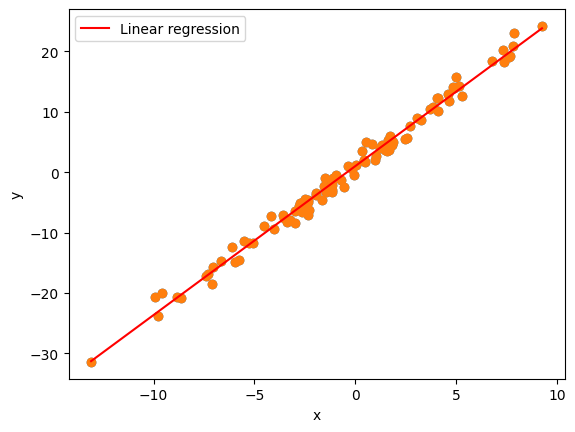

In [145]:
plt.scatter(x,y)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = w[0] * x_line + b

plt.scatter(x, y)
plt.plot(x_line, y_line, color="red", label="Linear regression")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

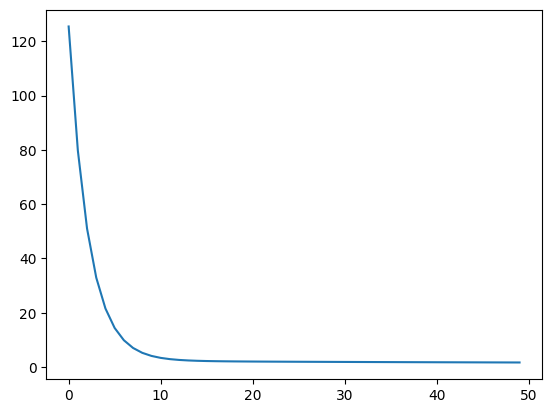

In [146]:
plt.plot(model.losses[:50])

In [147]:
from sklearn.linear_model import LinearRegression as skLinearRegression

m = skLinearRegression()
m.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.47]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.009
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[45.18]


In [148]:
my_loss = np.sum((y-model.predict(x))**2)/100
sk_loss = np.sum((y-m.predict(x))**2)/100

my_loss,sk_loss

(np.float64(1.2724317817856323), np.float64(1.2724307744994554))

In [149]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


data = fetch_california_housing()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [150]:
model = LinearRegression(max_iterations=5000, lr=0.2)
w, b = model.fit(X_train,y_train)
sk_model = skLinearRegression()
sk_model.fit(X_train, y_train)

print("My model")
print("w =", w)
print("b =", b)

print("\nScikit-learn")
print("w =", sk_model.coef_)
print("b =", sk_model.intercept_)

My model
w = [ 0.85480102  0.1226384  -0.29514896  0.33985269 -0.00227886 -0.04084831
 -0.89589667 -0.86885788]
b = 2.0719469373786197

Scikit-learn
w = [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]
b = 2.071946937378619


In [151]:
my_loss = np.mean((y_test - model.predict(X_test))**2)
sk_loss = np.mean((y_test - sk_model.predict(X_test))**2)

my_loss,sk_loss

(np.float64(0.55593627152953), np.float64(0.5558915986952442))

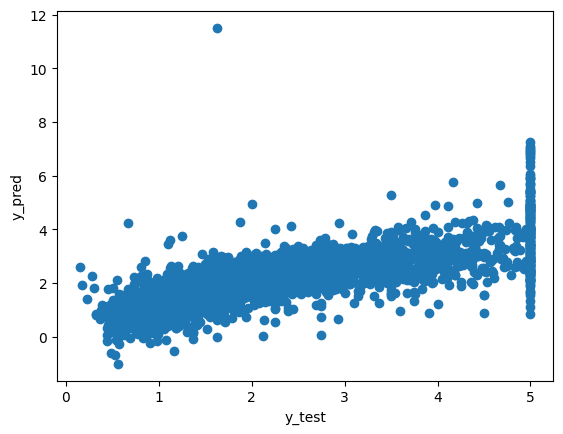

In [152]:
import matplotlib.pyplot as plt

plt.scatter(y_test, sk_model.predict(X_test))
plt.xlabel("y_test")
plt.ylabel("y_pred")
plt.show()

# Logistic Regression

### Goal

Predict the probability that an example belongs to a class, assuming a linear relationship between the input features $X$ and the log-odds of the target variable $Y$. Logistic Regression is commonly used for binary classification.

$$
z = Xw + b
$$

The predicted probability is obtained using the Sigmoid function:

$$
\hat{Y} = \sigma(z) = \frac{1}{1+e^{-z}}
$$

### Loss Function

Measure how well the predicted probability matches the actual binary label using Binary Cross-Entropy (BCE).

$$
L = -\left[y\log(\hat{y}) + (1-y)\log(1-\hat{y})\right]
$$

### Cost Function

Compute the average loss across $n$ training examples.

$$
J(w,b) = -\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i\log(\hat{y}_i)
+(1-y_i)\log(1-\hat{y}_i)
\right]
$$

### Prediction

Convert the predicted probability into a class label using a decision threshold, commonly 0.5.

$$
\hat{y}_{\text{class}} =
\begin{cases}
1 & \text{if } \hat{y} \geq 0.5\\
0 & \text{otherwise}
\end{cases}
$$

### Optimization

The parameters $w$ and $b$ are optimized using Gradient Descent to minimize the cost function and improve the predicted probabilities.

$$
w \leftarrow w - \alpha \frac{\partial J}{\partial w}
$$

$$
b \leftarrow b - \alpha \frac{\partial J}{\partial b}
$$

With the gradients:

$$
\frac{\partial J}{\partial w}
= \frac{1}{n}X^T(\hat{Y}-Y)
$$

$$
\frac{\partial J}{\partial b}
= \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)
$$

In [153]:
class LogisticRegression():

    def __init__(self, max_iterations=1000, lr=0.01, reg=None, lam=1, epsilon=1e-5):
        self.max_iterations=max_iterations
        self.lr=lr
        self.reg = reg
        self.lam = lam
        self.epsilon = epsilon
        self.losses = []

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def fit(self,X,y):
        self.n, self.d = X.shape
        self.w = np.zeros(self.d)
        self.b = 0
        self.X = X
        self.y = y

        for i in range(self.max_iterations):
            y_hat = self.predict(self.X)
            loss = np.sum((self.y - y_hat) ** 2) / self.n
            self.losses.append(loss)
            dw = (np.dot(self.X.T, (y_hat - y)))/self.n
            db = np.sum(y_hat - y)/self.n
            if self.reg == "l2":
              dw += (self.lam / n) * w
            if self.reg == "l1":
              dw += (self.lam / n) * np.sign(w)
            new_w = self.w - self.lr * dw
            new_b = self.b - self.lr * db
            if np.all(np.abs(new_w - self.w) <= self.epsilon) and abs(new_b - self.b) <= self.epsilon:
                return self.w, self.b
            else:
                self.w = new_w
                self.b = new_b

        return self.w, self.b

    def predict(self, x):
        return self._sigmoid(np.dot(x, self.w) + self.b)


In [154]:
np.random.seed(0)
n_samples = 100

X = np.random.rand(n_samples) * 10

probabilities = 1 / (1 + np.exp(-(X - 5)))
y = (np.random.rand(n_samples) < probabilities).astype(int)

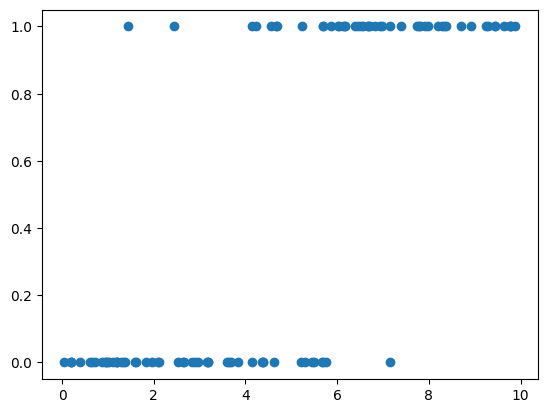

In [155]:
import matplotlib.pyplot as plt

plt.scatter(X,y)

In [156]:
model = LogisticRegression(max_iterations=5000, lr=0.05)
X = X.reshape(-1,1)
model.fit(X, y)

(array([1.01373709]), np.float64(-4.985622053638025))

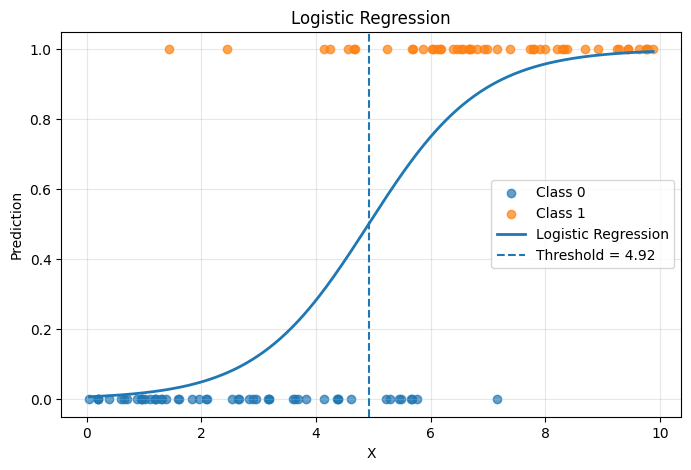

In [157]:
w = model.w[0]
b = model.b
x_threshold = -b / w

x_plot = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
y_plot = model.predict(x_plot)

plt.figure(figsize=(8, 5))

plt.scatter(X[y == 0], y[y == 0], label="Class 0", alpha=0.7)
plt.scatter(X[y == 1], y[y == 1], label="Class 1", alpha=0.7)

plt.plot(x_plot, y_plot, label="Logistic Regression", linewidth=2)
plt.axvline(x_threshold, linestyle="--", label=f"Threshold = {x_threshold:.2f}")

plt.xlabel("X")
plt.ylabel("Prediction")
plt.title("Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [158]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target

In [159]:
X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [160]:
from sklearn.linear_model import LogisticRegression as skLogisticRegression
model = LogisticRegression(max_iterations=5000, lr=0.05)
w, b = model.fit(X_train,y_train)

sk_model = skLogisticRegression(max_iter=5000, )
sk_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [161]:
sk_model.coef_, sk_model.intercept_

(array([[-0.43464701, -0.39719369, -0.39606985, -0.46999027, -0.06739432,
          0.52671658, -0.80767618, -1.1077114 ,  0.24153785,  0.07844689,
         -1.25057276,  0.1889927 , -0.58988574, -0.91987672, -0.31656977,
          0.66906627,  0.17107672, -0.31431731,  0.50499861,  0.61176062,
         -0.87394431, -1.35751246, -0.58604724, -0.83803013, -0.54737794,
          0.00589749, -0.95168648, -0.78040785, -1.19559714, -0.16293183]]),
 array([0.32857199]))

In [162]:
w,b

(array([-0.53502741, -0.62079618, -0.49876325, -0.59536533, -0.15574041,
         0.46816032, -0.84924192, -1.0263656 ,  0.210571  ,  0.2709791 ,
        -1.29874564,  0.14585506, -0.77734603, -0.96609152, -0.30400336,
         0.89256529,  0.01497584, -0.28870859,  0.49654748,  0.7311598 ,
        -0.98233694, -1.38451196, -0.76808451, -0.95250662, -0.80310101,
        -0.03637253, -1.0346711 , -0.95222393, -1.26763289, -0.18094637]),
 np.float64(0.3759490970742286))

My model
Accuracy: 0.9912280701754386


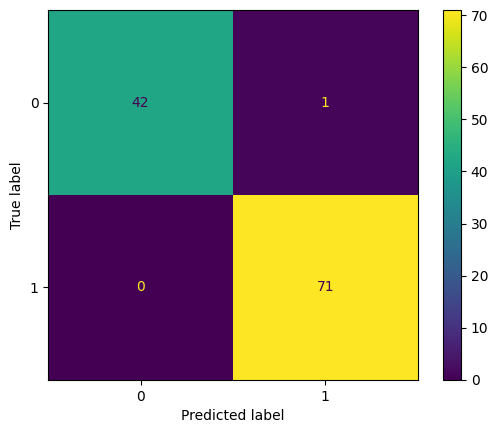

In [163]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
y_pred_sk = sk_model.predict(X_test)

print("My model")
print("Accuracy:", accuracy_score(y_test, y_pred > 0.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred > 0.5)
plt.show()



Scikit-learn
Accuracy: 0.9736842105263158


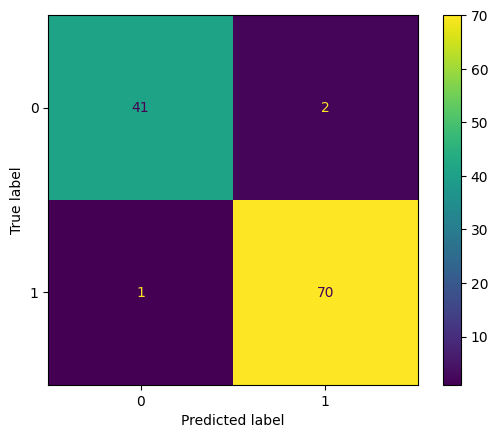

In [164]:
print("\nScikit-learn")
print("Accuracy:", accuracy_score(y_test, y_pred_sk))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_sk > 0.5)
plt.show()